## 0 · Config

In [1]:
import os, sys, glob, json, time, warnings
import numpy as np
import pandas as pd

DATA_DIR = "/kaggle/input/competitions/rsna-knee-abnormality-detection"
WORK     = "/kaggle/working"

IMG        = 224          # in-plane resolution
N_SLICES   = 16           # slices resampled per series
PLANES     = ["Sagittal", "Coronal", "Axial"]   # fixed slot order -- slot i is always plane i
N_SLOTS    = len(PLANES)

CACHE = os.path.join(WORK, "cache.npy")
INDEX = os.path.join(WORK, "cache_index.csv")
STATE = os.path.join(WORK, "cache_done.npy")

warnings.filterwarnings("ignore", category=UserWarning)
assert os.path.isdir(DATA_DIR), f"attach the competition dataset ({DATA_DIR} missing)"
print("files:", sorted(os.listdir(DATA_DIR)))

files: ['sample_submission.csv', 'test.csv', 'test_series', 'test_series.csv', 'train.csv', 'train_series', 'train_series.csv']


In [2]:
# Compressed transfer syntaxes (JPEG Lossless, JPEG 2000) need a decoder backend.
# pydicom alone raises on them. Internet must be ON for this cell.
try:
    import pylibjpeg, pylibjpeg_libjpeg, pylibjpeg_openjpeg   # noqa: F401
    print("pylibjpeg backends already present")
except ImportError:
    !pip install -q pylibjpeg pylibjpeg-libjpeg pylibjpeg-openjpeg
    print("installed pylibjpeg backends")

import pydicom
import cv2
print("pydicom", pydicom.__version__, "| cv2", cv2.__version__)
print("\nNOTE: your *submission* notebook runs offline and will need these same")
print("decoders. Check whether the Kaggle image already ships them; if not, add")
print("them as a pip-wheel dataset before you build the inference notebook.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 62.0 MB/s eta 0:00:00
installed pylibjpeg backends
pydicom 3.0.2 | cv2 4.13.0

NOTE: your *submission* notebook runs offline and will need these same
decoders. Check whether the Kaggle image already ships them; if not, add
them as a pip-wheel dataset before you build the inference notebook.


## 1 · Load the tables and choose one series per plane

In [3]:
train        = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
train_series = pd.read_csv(os.path.join(DATA_DIR, "train_series.csv"))

train_series["series_dir"] = [
    os.path.join(DATA_DIR, "train_series", st, se)
    for st, se in zip(train_series["StudyInstanceUID"], train_series["SeriesInstanceUID"])
]
train_series["Fluid_Sensitive"] = pd.to_numeric(
    train_series["Fluid_Sensitive"], errors="coerce").fillna(0).astype(int)
train_series["Fat_Suppression"] = pd.to_numeric(
    train_series["Fat_Suppression"], errors="coerce").fillna(0).astype(int)

print(f"{len(train):,} studies | {len(train_series):,} series")
print(train_series.groupby(["Anatomical_Plane", "Fluid_Sensitive"]).size().to_string())

4,407 studies | 24,371 series
Anatomical_Plane  Fluid_Sensitive
Axial             0                  1179
                  1                  4719
Coronal           0                  3985
                  1                  4624
Sagittal          0                  5197
                  1                  4667


In [4]:
def n_files(d):
    try:
        return len(os.listdir(d))
    except OSError:
        return 0


# Counting files for every series takes a couple of minutes; it is worth it, because
# picking a 3-slice localiser over a real 30-slice acquisition would be silent damage.
t0 = time.time()
train_series["n_slices"] = [n_files(d) for d in train_series["series_dir"]]
print(f"counted slices in {time.time()-t0:.0f}s")
print(train_series["n_slices"].describe().round(1).to_string())

counted slices in 271s
count    24371.0
mean        33.6
std         26.6
min         11.0
25%         25.0
50%         30.0
75%         34.0
max        320.0


In [5]:
# Slot selection. Fluid-sensitive first (that is where effusion, contusion,
# synovitis and most tears are visible at all), then the longest acquisition.
MIN_SLICES = 8

def choose(study_df):
    picked = {}
    for plane in PLANES:
        cand = study_df[(study_df["Anatomical_Plane"] == plane)
                        & (study_df["n_slices"] >= MIN_SLICES)]
        if not len(cand):
            cand = study_df[study_df["Anatomical_Plane"] == plane]
        if not len(cand):
            continue
        cand = cand.sort_values(["Fluid_Sensitive", "n_slices"], ascending=[False, False])
        picked[plane] = cand.iloc[0]
    return picked


rows = []
for uid, g in train_series.groupby("StudyInstanceUID", sort=False):
    picked = choose(g)
    rec = {"StudyInstanceUID": uid}
    for i, plane in enumerate(PLANES):
        s = picked.get(plane)
        rec[f"dir_{i}"]    = s["series_dir"] if s is not None else ""
        rec[f"fluid_{i}"]  = int(s["Fluid_Sensitive"]) if s is not None else 0
        rec[f"nsl_{i}"]    = int(s["n_slices"]) if s is not None else 0
    rows.append(rec)

manifest = pd.DataFrame(rows)
manifest = train[["StudyInstanceUID"]].merge(manifest, on="StudyInstanceUID", how="left")
for i in range(N_SLOTS):
    manifest[f"dir_{i}"] = manifest[f"dir_{i}"].fillna("")
    manifest[f"nsl_{i}"] = manifest[f"nsl_{i}"].fillna(0).astype(int)

print("plane coverage across studies:")
for i, plane in enumerate(PLANES):
    have = (manifest[f"dir_{i}"] != "").mean()
    fluid = manifest.loc[manifest[f"dir_{i}"] != "", f"fluid_{i}"].mean()
    print(f"  {plane:<9} present {have:6.1%}   of those, fluid-sensitive {fluid:6.1%}")

n_planes = sum((manifest[f"dir_{i}"] != "").astype(int) for i in range(N_SLOTS))
print("\nplanes per study:", n_planes.value_counts().sort_index().to_dict())
print("studies with none:", int((n_planes == 0).sum()))

plane coverage across studies:
  Sagittal  present 100.0%   of those, fluid-sensitive  94.2%
  Coronal   present 100.0%   of those, fluid-sensitive  96.4%
  Axial     present 100.0%   of those, fluid-sensitive 100.0%

planes per study: {3: 4407}
studies with none: 0


## 2 · The decoder

Read headers only to establish slice order, pick `N_SLICES` evenly across the stack,
then decode **just those**. That is ~210k decodes instead of ~400k.

Normalisation is per-series 1–99th percentile, because intensities are not comparable
across scanners, vendors or sequences. Output is `uint8` — a 4× saving over float16
with no meaningful loss after that normalisation.

In [6]:
def _sort_key(ds):
    # Project the slice position onto the stack normal. The normal's SIGN depends on
    # how the scanner wrote ImageOrientationPatient, so two studies of the same knee
    # can come out in opposite order. Canonicalise by forcing the normal's dominant
    # component positive -> every sagittal stack runs the same anatomical direction.
    iop = getattr(ds, "ImageOrientationPatient", None)
    ipp = getattr(ds, "ImagePositionPatient", None)
    if iop is not None and ipp is not None:
        try:
            n = np.cross(np.array(iop[:3], float), np.array(iop[3:6], float))
            n = n * np.sign(n[np.argmax(np.abs(n))] or 1.0)
            return float(np.dot(np.array(ipp, float), n))
        except Exception:
            pass
    return float(getattr(ds, "InstanceNumber", 0) or 0)


def load_series(series_dir, n_slices=N_SLICES, img=IMG):
    # -> (n_slices, img, img) uint8, ordered through-plane. Raises on failure.
    files = glob.glob(os.path.join(series_dir, "*.dcm"))
    if not files:
        raise FileNotFoundError(series_dir)

    # headers only: cheap, and enough to order the stack
    keyed = []
    for f in files:
        try:
            ds = pydicom.dcmread(f, stop_before_pixels=True)
            keyed.append((_sort_key(ds), f))
        except Exception:
            continue
    if not keyed:
        raise RuntimeError("no readable headers")
    keyed.sort(key=lambda t: t[0])
    ordered = [f for _, f in keyed]

    # evenly spaced picks; repeats the ends when the series is shorter than n_slices
    idx = np.linspace(0, len(ordered) - 1, n_slices).round().astype(int)

    out = np.zeros((n_slices, img, img), dtype=np.float32)
    ok = 0
    for j, i in enumerate(idx):
        try:
            ds = pydicom.dcmread(ordered[i])
            a = ds.pixel_array.astype(np.float32)
            m = float(getattr(ds, "RescaleSlope", 1) or 1)
            b = float(getattr(ds, "RescaleIntercept", 0) or 0)
            if (m, b) != (1.0, 0.0):
                a = a * m + b
            if getattr(ds, "PhotometricInterpretation", "") == "MONOCHROME1":
                a = a.max() - a
            if a.ndim == 3:                      # rare colour/multiframe slice
                a = a.mean(axis=-1)
            out[j] = cv2.resize(a, (img, img), interpolation=cv2.INTER_AREA)
            ok += 1
        except Exception:
            continue                              # leave the slice black
    if ok == 0:
        raise RuntimeError("no decodable slices")

    # Percentiles over the WHOLE volume: shift- and scale-invariant, so RescaleSlope /
    # RescaleIntercept cannot change the output. Masking to out > 0 breaks that.
    lo, hi = np.percentile(out, [1, 99])
    if hi <= lo:
        lo, hi = float(out.min()), float(out.max())
    if hi <= lo:
        hi = lo + 1.0
    return np.clip((out - lo) / (hi - lo) * 255.0, 0, 255).astype(np.uint8)

(16, 224, 224) uint8 | range [0, 255] | 0.35s for one series
projected full run: 19 min on 4 processes


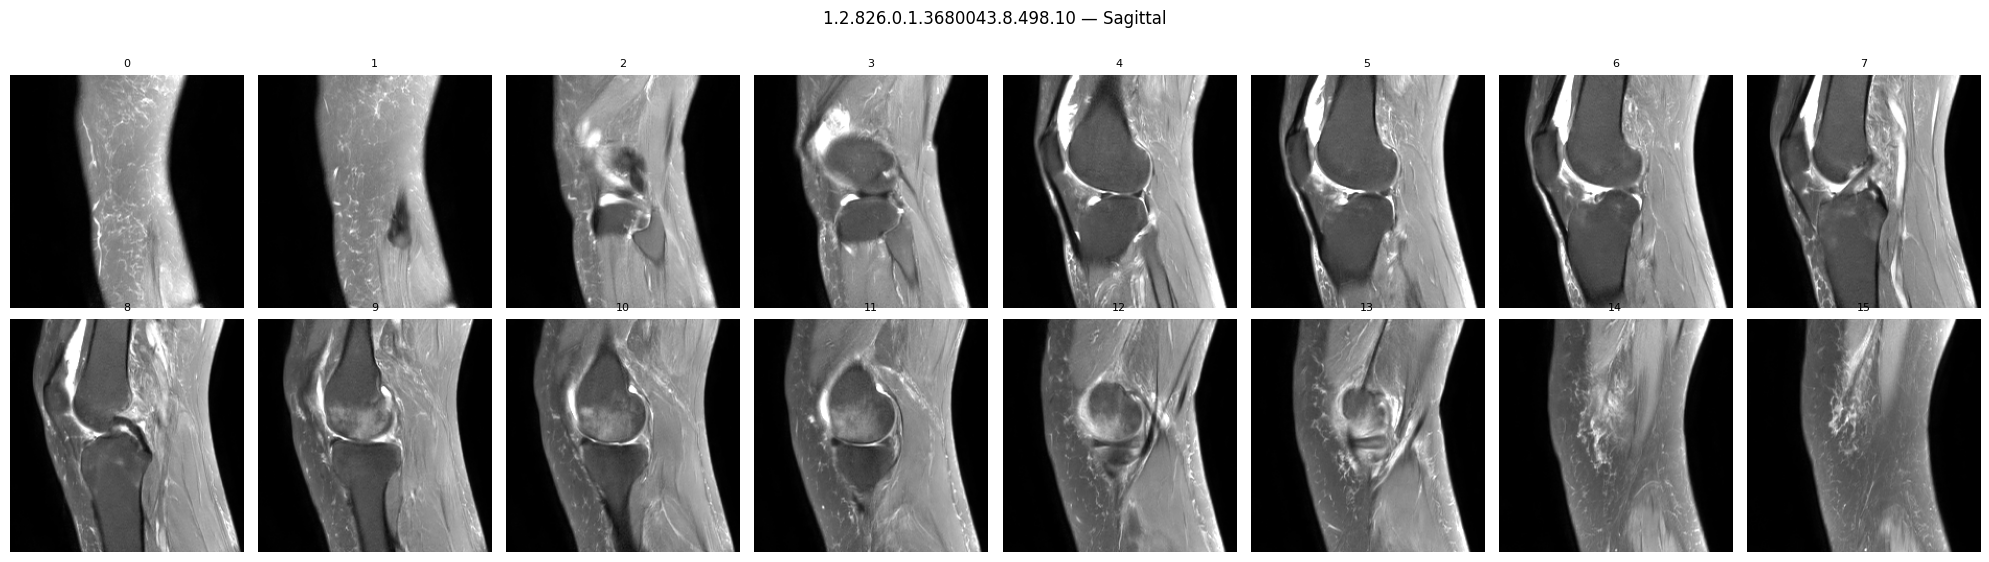

In [7]:
# smoke test before committing hours to the full run
probe = manifest[manifest["dir_0"] != ""].iloc[0]
t0 = time.time()
vol = load_series(probe["dir_0"])
dt = time.time() - t0
print(f"{vol.shape} {vol.dtype} | range [{vol.min()}, {vol.max()}] | {dt:.2f}s for one series")
print(f"projected full run: {dt * len(manifest) * N_SLOTS / 4 / 60:.0f} min on 4 processes")

import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 8, figsize=(20, 5.5))
for k, ax in enumerate(axes.ravel()):
    ax.imshow(vol[k], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{k}", fontsize=8); ax.axis("off")
plt.suptitle(f"{probe['StudyInstanceUID'][:28]} — {PLANES[0]}", y=1.02)
plt.tight_layout(); plt.show()

## 3 · Fill the cache

One memmap of shape `(N, 3, N_SLICES, IMG, IMG)`. Workers open it `r+` and write
their own row, so there is no shared state and no lock. A boolean `done` array makes
it resumable — if the session dies, re-run and it continues.

In [8]:
N = len(manifest)
SHAPE = (N, N_SLOTS, N_SLICES, IMG, IMG)
nbytes = int(np.prod(SHAPE))
print(f"cache shape {SHAPE} -> {nbytes/1e9:.1f} GB")
assert nbytes < 19e9, "over the 20 GB output cap -- reduce IMG or N_SLICES"

if not os.path.exists(CACHE):
    np.lib.format.open_memmap(CACHE, mode="w+", dtype=np.uint8, shape=SHAPE).flush()
    print("allocated", CACHE)

done = (np.load(STATE) if os.path.exists(STATE)
        else np.zeros(N, dtype=bool))
print(f"{done.sum():,}/{N:,} studies already cached")

cache shape (4407, 3, 16, 224, 224) -> 10.6 GB
allocated /kaggle/working/cache.npy
0/4,407 studies already cached


In [9]:
from concurrent.futures import ProcessPoolExecutor, ThreadPoolExecutor
import multiprocessing as mp

# Workers inherit load_series() and DIRS through fork. Under "spawn" the child would
# re-import __main__, which a notebook cannot provide -- so pin fork, and fall back
# to threads if it is unavailable (decode releases the GIL, so threads still help).
try:
    _CTX = mp.get_context("fork")
    def _pool(n): return ProcessPoolExecutor(max_workers=n, mp_context=_CTX)
    _KIND = "processes (fork)"
except ValueError:
    def _pool(n): return ThreadPoolExecutor(max_workers=n)
    _KIND = "threads (fork unavailable)"
print("parallelism:", _KIND, "|", os.cpu_count(), "cpus")

DIRS = [[manifest[f"dir_{i}"].iloc[r] for i in range(N_SLOTS)] for r in range(N)]


def fill_row(r):
    mm = np.lib.format.open_memmap(CACHE, mode="r+")
    filled = []
    for slot, d in enumerate(DIRS[r]):
        if not d:
            continue
        try:
            mm[r, slot] = load_series(d)
            filled.append(slot)
        except Exception:
            pass
    del mm
    return r, filled


todo = [r for r in range(N) if not done[r]]
print(f"{len(todo):,} to do")

t0, n_ok = time.time(), 0
present = np.zeros((N, N_SLOTS), dtype=bool)
if os.path.exists(INDEX):
    prev = pd.read_csv(INDEX)
    for i in range(N_SLOTS):
        present[:, i] = prev[f"present_{i}"].to_numpy(dtype=bool)

with _pool(os.cpu_count()) as ex:
    for k, (r, filled) in enumerate(ex.map(fill_row, todo, chunksize=8), 1):
        done[r] = True
        present[r, filled] = True
        n_ok += bool(filled)
        if k % 200 == 0 or k == len(todo):
            el = time.time() - t0
            print(f"  {k:,}/{len(todo):,} | {k/el:.1f} studies/s | "
                  f"eta {(len(todo)-k)/max(k/el,1e-9)/60:.0f} min")
            np.save(STATE, done)

np.save(STATE, done)
print(f"\ndone. {done.sum():,}/{N:,} cached, {n_ok:,} with at least one series this pass")

parallelism: processes (fork) | 4 cpus
4,407 to do
  200/4,407 | 2.2 studies/s | eta 32 min
  400/4,407 | 2.1 studies/s | eta 32 min
  600/4,407 | 2.2 studies/s | eta 29 min
  800/4,407 | 2.2 studies/s | eta 27 min
  1,000/4,407 | 2.3 studies/s | eta 24 min
  1,200/4,407 | 2.4 studies/s | eta 22 min
  1,400/4,407 | 2.4 studies/s | eta 21 min
  1,600/4,407 | 2.5 studies/s | eta 19 min
  1,800/4,407 | 2.5 studies/s | eta 18 min
  2,000/4,407 | 2.5 studies/s | eta 16 min
  2,200/4,407 | 2.5 studies/s | eta 15 min
  2,400/4,407 | 2.5 studies/s | eta 13 min
  2,600/4,407 | 2.5 studies/s | eta 12 min
  2,800/4,407 | 2.5 studies/s | eta 11 min
  3,000/4,407 | 2.5 studies/s | eta 9 min
  3,200/4,407 | 2.5 studies/s | eta 8 min
  3,400/4,407 | 2.5 studies/s | eta 7 min
  3,600/4,407 | 2.5 studies/s | eta 5 min
  3,800/4,407 | 2.5 studies/s | eta 4 min
  4,000/4,407 | 2.5 studies/s | eta 3 min
  4,200/4,407 | 2.5 studies/s | eta 1 min
  4,400/4,407 | 2.5 studies/s | eta 0 min
  4,407/4,407 | 2.5

## 4 · Verify and index

In [10]:
index = manifest[["StudyInstanceUID"]].copy()
for i in range(N_SLOTS):
    index[f"present_{i}"] = present[:, i]
    index[f"fluid_{i}"]   = manifest[f"fluid_{i}"].to_numpy()
index["row"] = np.arange(N)
index["n_present"] = present.sum(axis=1)
index.to_csv(INDEX, index=False)

print("cached planes per study:", index["n_present"].value_counts().sort_index().to_dict())
print("\nper-plane success:")
for i, plane in enumerate(PLANES):
    wanted = (manifest[f"dir_{i}"] != "").sum()
    got = int(present[:, i].sum())
    print(f"  {plane:<9} {got:,}/{wanted:,} ({got/max(wanted,1):.1%})")

dead = index[index["n_present"] == 0]
print(f"\nstudies with NO usable series: {len(dead)}")
if len(dead):
    print("  (drop these from training; they cannot contribute)")
    display(dead.head())

cached planes per study: {3: 4407}

per-plane success:
  Sagittal  4,407/4,407 (100.0%)
  Coronal   4,407/4,407 (100.0%)
  Axial     4,407/4,407 (100.0%)

studies with NO usable series: 0


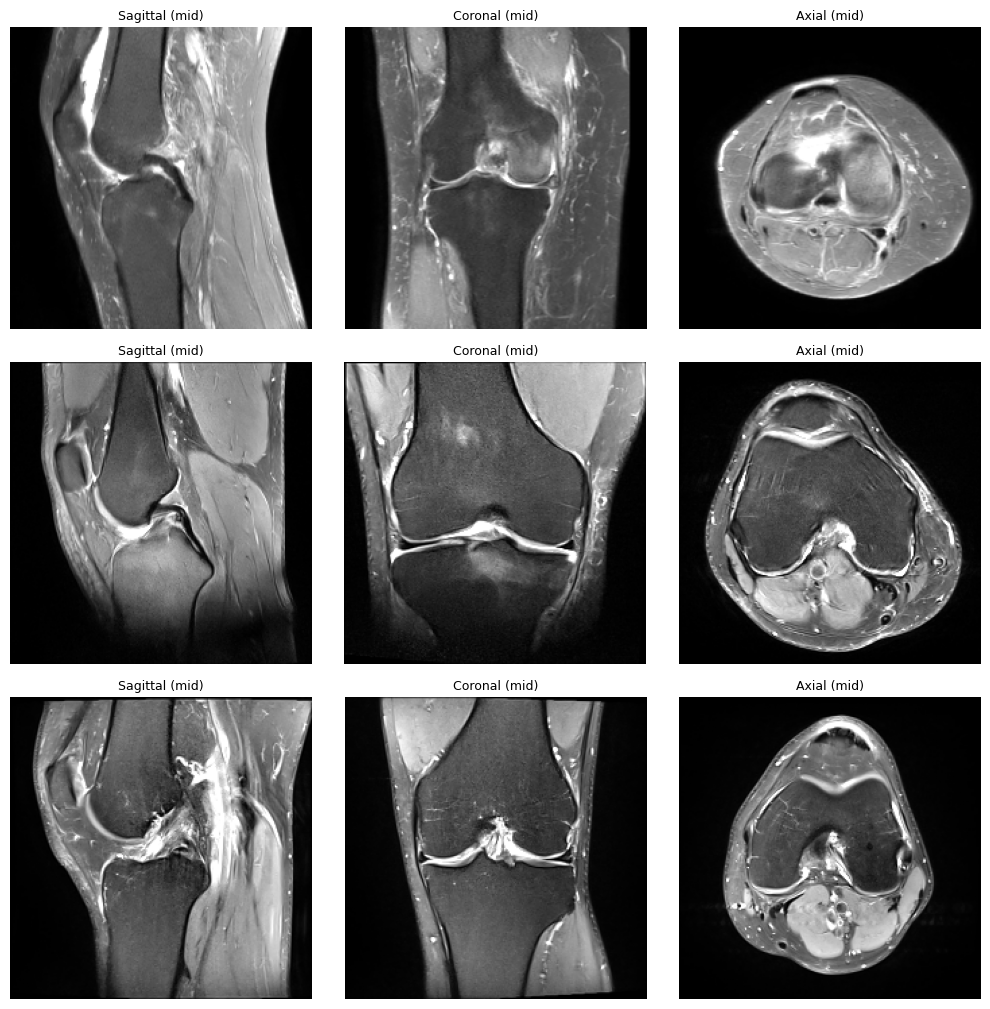

non-zero fraction on sagittal slot: [0.814, 0.888, 0.933]

if any of these look blank or scrambled, stop and inspect before training.


In [11]:
# read back a few rows exactly the way training will
mm = np.load(CACHE, mmap_mode="r")
sample = index[index["n_present"] == N_SLOTS].head(3)

fig, axes = plt.subplots(len(sample), N_SLOTS, figsize=(3.4*N_SLOTS, 3.4*len(sample)))
axes = np.atleast_2d(axes)
for a, (_, row) in enumerate(sample.iterrows()):
    for b in range(N_SLOTS):
        img = mm[row["row"], b, N_SLICES // 2]
        axes[a, b].imshow(img, cmap="gray", vmin=0, vmax=255)
        axes[a, b].set_title(f"{PLANES[b]} (mid)", fontsize=9)
        axes[a, b].axis("off")
plt.tight_layout(); plt.show()

nz = [float((mm[r, s] > 0).mean()) for r, s in
      zip(sample["row"], [0]*len(sample))]
print("non-zero fraction on sagittal slot:", [round(x, 3) for x in nz])
print("\nif any of these look blank or scrambled, stop and inspect before training.")

## 5 · Save and hand off

**Save Version → Save & Run All.** `cache.npy` and `cache_index.csv` become this
notebook's output; attach it as an input to the training notebook and read it with
`np.load(path, mmap_mode="r")` — no decompression, no DICOM, near-zero CPU per batch.

Two things to carry forward:

- Slot order is fixed: **0 = Sagittal, 1 = Coronal, 2 = Axial**. Feed the slot index
  to the model, or keep separate heads per plane — sagittal carries ACL and menisci,
  coronal the collaterals and tibiofemoral compartments, axial the patellofemoral
  joint and effusion.
- `present_{i}` marks which slots are real. Zero-filled slots must be masked in the
  model's series pooling, exactly like NaN labels are masked in the loss.

For the **submission** notebook: `load_series()` above is the function to reuse on
test DICOMs at inference time. It needs the JPEG decoder backends, and that notebook
runs offline — verify they exist in the image or ship them as a wheel dataset.